## <b>Intelligence Artificielle pour le Véhicule Autonome -> Notebook n°1</b>

#### <b>Exercice 1.1 : Drapeau français</b>

Générer une image du drapeau français, d'une largeur de 200 pixels (et sachant que le rapport hauteur/largeur est 2/3), avec la bonne couleur du bleu, et l'afficher. En utilisant les fonction d'OpenCV, générer un fichier image que vous pourrez télécharger sur votre machine.

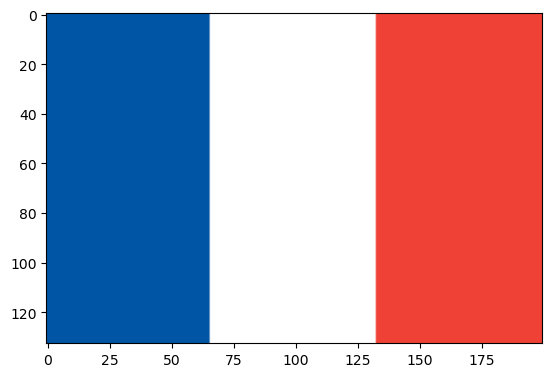

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

largeur = 200
hauteur = int(largeur * (2/3))

drapeau = np.zeros((hauteur, largeur, 3), dtype=np.uint8)

# Définir les couleurs (RGB)
bleu = (0, 85, 164)
blanc = (255, 255, 255)
rouge = (239, 65, 53)

drapeau[:, 0:largeur//3] = bleu
drapeau[:, largeur//3:2*largeur//3] = blanc
drapeau[:, 2*largeur//3:largeur] = rouge
plt.imshow(drapeau)

drapeaufr = Image.fromarray(drapeau)
drapeaufr.save('drapeaufr.png')


#### <b>Exercice 1.2 : Affichage d'un extrait du dataset GTSRB</b>

Afficher les 10 premières images de chaque classes du dataset GTSRB (sur une seule ligne pour chaque classe), en les redimensionnant au préalable à la taille 50x50 (ou mieux, à la taille max des images présentes dans le dataset.

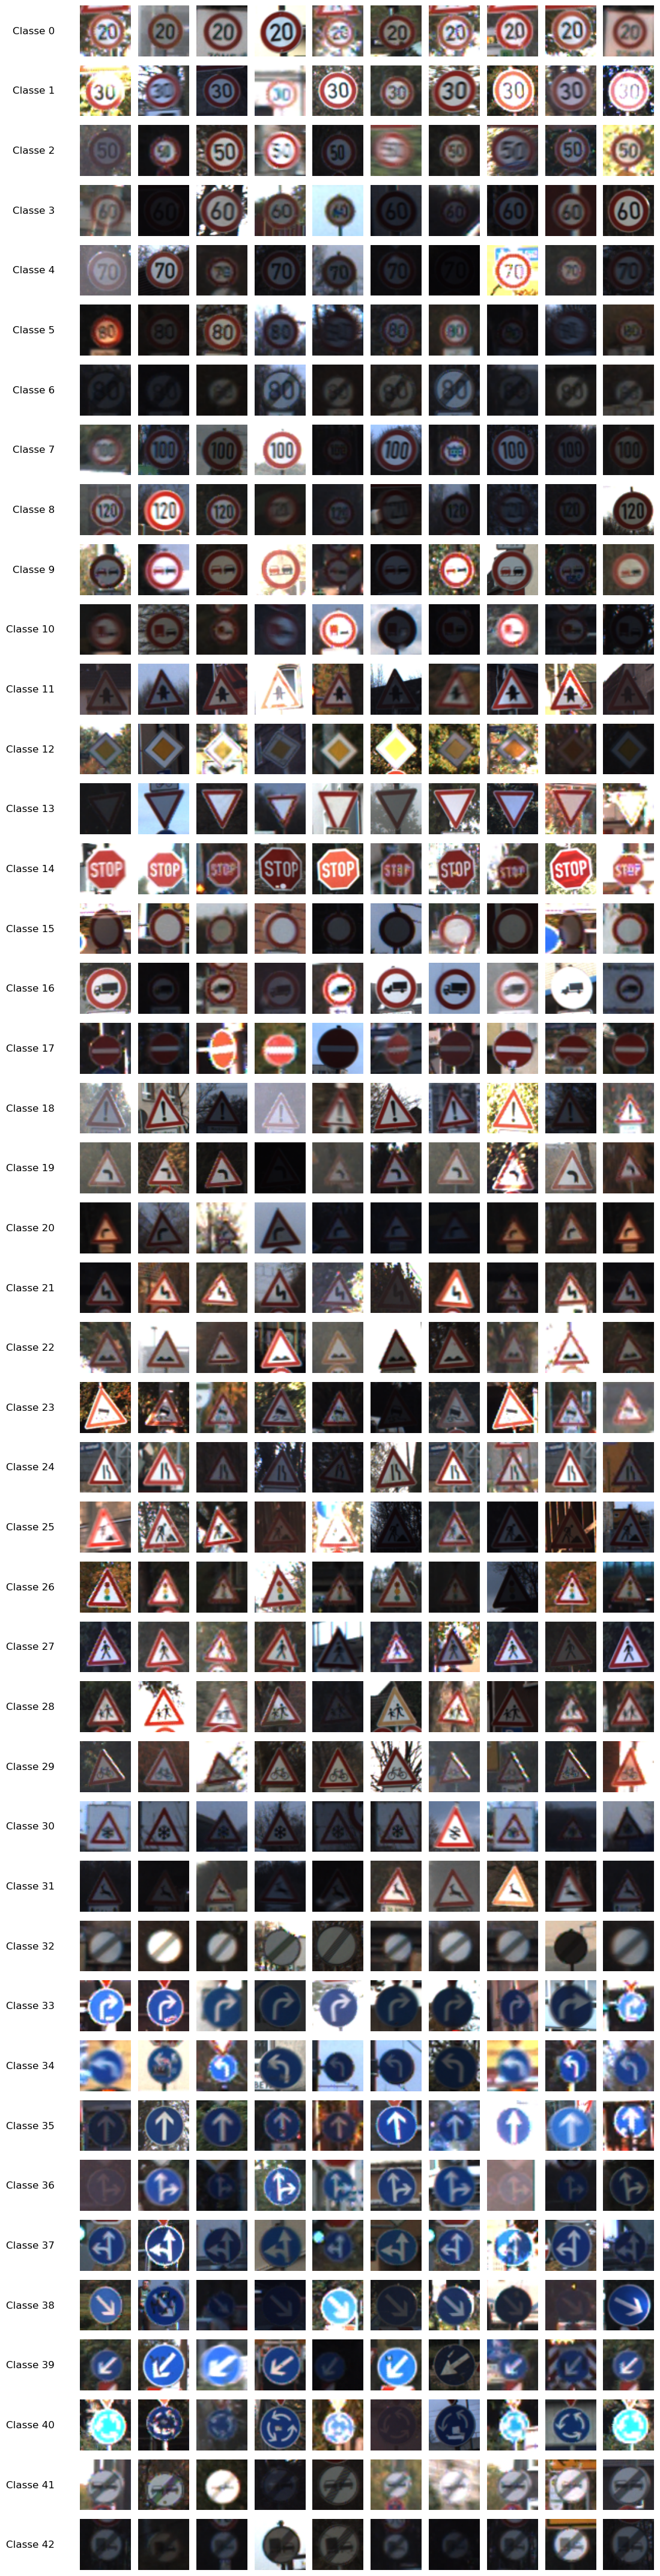

In [12]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Chemin vers le dossier où les images sont stockées

data_dir = '/home/jovyan/iadatasets/GTSRB/Final_Training/Images'

# Paramètres d'affichage
num_classes = 43  # Nombre de classes dans le dataset GTSRB
num_images = 10   # Nombre d'images à afficher par classe
size = (50, 50)   # Taille de redimensionnement

# Créer une figure pour afficher les images
fig, axes = plt.subplots(num_classes, num_images, figsize=(num_images + 1, num_classes), squeeze=False)

# Parcourir chaque classe
for class_id in range(num_classes):
    class_path = os.path.join(data_dir, f'{class_id:05d}')  # Les dossiers sont nommés 00000, 00001, etc.
    
    # Obtenir les fichiers d'image de la classe
    images = [f for f in os.listdir(class_path) if f.endswith('.ppm')][:num_images]
    
    for img_id, ax in zip(images, axes[class_id]):
        # Charger l'image
        img_path = os.path.join(class_path, img_id)
        img = Image.open(img_path)
        
        # Redimensionner l'image
        img_maj = img.resize(size)
        
        # Afficher l'image
        ax.imshow(img_maj)
        ax.axis('off')  # Masquer les axes

    # Ajout du numéro de la classe à gauche de chaque ligne
    axes[class_id][0].text(-0.5, 0.5, f'Classe {class_id}', fontsize=12, va='center', ha='right', transform=axes[class_id][0].transAxes)

plt.tight_layout()
plt.show()

#### <b>Exercice 1.3 : Affichage de Sammon en 3D des données Iris</b>

Réaliser un affichage 3D des données Iris, en utilisant la méthode de Sammon et en choisissant un point de vue adéquat pour distinguer au mieux les classes.
Que peut-on conclure de cet affichage sur la facilité ou la difficulté de séparer les classes par un classifieur ?

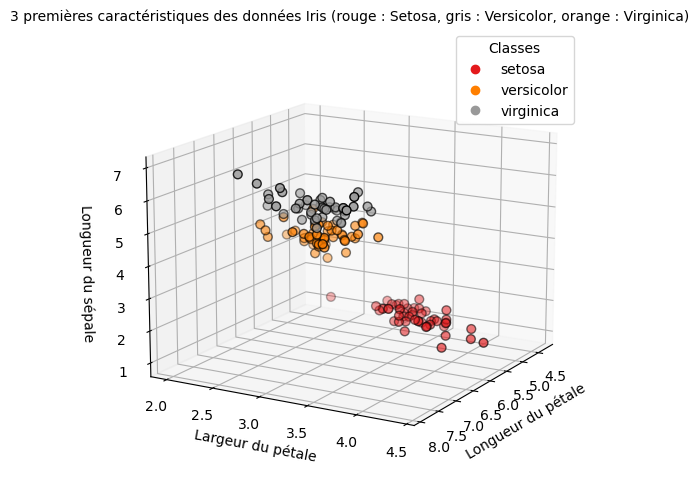

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn import datasets

# Charger le dataset Iris
iris = datasets.load_iris()
data = iris.data[:, :3]  # 3 premières caractéristiques
label = iris.target
target_names = iris.target_names

# Créer une figure 3D
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# les points
scatter = ax.scatter3D(data[:, 0], data[:, 1], data[:, 2], c=label, cmap=plt.cm.Set1, edgecolor='k', s=40)

# Étiquettes et titre
ax.set_title("3 premières caractéristiques des données Iris (rouge : Setosa, gris : Versicolor, orange : Virginica)", size=10)
ax.set_xlabel("Longueur du pétale")
ax.set_ylabel("Largeur du pétale")
ax.set_zlabel("Longueur du sépale")

# Ajuster le point de vue
ax.view_init(elev=15, azim=30)  # modifier l'angle

# Afficher la légende
handles, labels = scatter.legend_elements()
ax.legend(handles, target_names, title="Classes")

# Afficher le graphique
plt.show()


#### <b>Exercice 1.4 : Manipulation du dataset Digit</b>

a) <b>Calculer la distance euclidienne</b> entre 2 images du dataset : 
- d'abord 2 images qui se ressemblent
- puis 2 images très différentes
Conclure sur le lien entre la ressemblance entre 2 images et la distance entre elles.

In [19]:
from sklearn.datasets import load_digits
from scipy.spatial import distance

# load dataset
digits = load_digits()
data = digits.data
labels = digits.target

# deux images du chiffre 1
img1 = data[labels == 1][0] 
img2 = data[labels == 1][1] 

# une image de 1 et une image de 9)
img3 = data[labels == 3][0]  # Image de 3
img4 = data[labels == 8][0]  # Image de 8

# distance euclidienne
distance_similar = distance.euclidean(img1, img2)
distance_different = distance.euclidean(img3, img4)

print("Distance entre images similaires:", distance_similar)
print("Distance entre images différentes:", distance_different)

Distance entre images similaires: 35.12833614050059
Distance entre images différentes: 42.44997055358225


b) <b>Normaliser</b> les images du dataset Digit et afficher une de ses images une fois normalisée (en mode texte).
Vérifier le résultat de cette normalisation en affichant la valeur moyenne et les pixels min et max. Une fois normalisées, afficher les pixels de l'une des images choisie au hasard.

Image normalisée (en mode texte) :
[[0.     0.     0.     0.75   0.8125 0.3125 0.     0.    ]
 [0.     0.     0.     0.6875 1.     0.5625 0.     0.    ]
 [0.     0.     0.1875 0.9375 1.     0.375  0.     0.    ]
 [0.     0.4375 0.9375 1.     1.     0.125  0.     0.    ]
 [0.     0.     0.0625 1.     1.     0.1875 0.     0.    ]
 [0.     0.     0.0625 1.     1.     0.375  0.     0.    ]
 [0.     0.     0.0625 1.     1.     0.375  0.     0.    ]
 [0.     0.     0.     0.6875 1.     0.625  0.     0.    ]]

Valeur moyenne des pixels de l'image : 0.3056640625
Valeur minimale des pixels de l'image : 0.0
Valeur maximale des pixels de l'image : 1.0


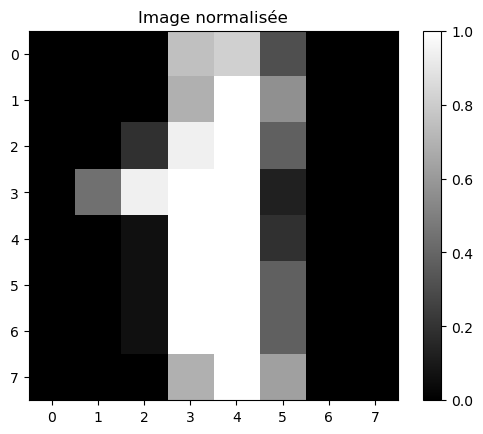

In [29]:
import numpy as np
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt

# Charger le dataset
digits = load_digits()
data = digits.data

# Normaliser les images
data_normalized = data / 16.0

# Afficher une image normalisée en mode texte
random_image = data_normalized[1].reshape(8, 8)# changer ici pour afficher d'autre digit
print("Image normalisée (en mode texte) :")
print(random_image)

#min et max de l'image normalisée
mean_value = np.mean(random_image)
min_value = np.min(random_image)
max_value = np.max(random_image)

print("\nValeur moyenne des pixels de l'image :", mean_value)
print("Valeur minimale des pixels de l'image :", min_value)
print("Valeur maximale des pixels de l'image :", max_value)

# Afficher l'image normalisée graphiquement pour vérifier visuellement
plt.imshow(random_image, cmap='gray')
plt.title('Image normalisée')
plt.colorbar()
plt.show()